# Veo Football Analytics Sprint: starter notebook

Loads the dataset, draws a pitch, and builds a few standard views. Everything below
runs in seconds. Read `DATA_DICTIONARY.md` alongside it.

**Three things that will save you time**
- The pitch plane is `x` / `y`
- Every file shares one clock, `timestamp_ms`
- Teams swap ends at half-time. Use the `attack_dir` column


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

summary = pd.read_csv("player_summary.csv")
events  = pd.read_csv("events.csv")
players = pd.read_parquet("players.parquet")   # ball is already joined in

print(f"summary {len(summary):>7,} rows   events  {len(events):>7,} rows")
print(f"players {len(players):>7,} rows")
summary.head()

summary      33 rows   events    1,289 rows
players 322,451 rows


,player_id,team,role,minutes_played,distance_km,top_speed_kmh,sprints,touches,passes,passes_completed,pass_completion_pct,shots,goals,dribbles,tackles,interceptions,duels
0,away_1,away,goalkeeper,96.0,4.72,23.8,0,38,27,17,63.0,0,0,0,0,4,0
1,away_10,away,outfield,68.6,8.21,30.1,10,33,19,11,57.9,3,0,2,4,1,2
2,away_11,away,outfield,62.7,6.68,28.0,4,20,9,8,88.9,3,0,0,1,0,6
3,away_12,away,outfield,95.5,11.33,27.0,4,85,58,40,69.0,0,0,3,4,10,9
4,away_13,away,outfield,41.2,4.52,27.2,2,15,8,4,50.0,0,0,0,3,3,0


## 1. The match in one table

No code needed for this bit: it's `player_summary.csv`.


In [2]:
cols = ["player_id", "minutes_played", "distance_km", "top_speed_kmh",
        "sprints", "passes", "pass_completion_pct", "shots", "goals"]
summary.sort_values("distance_km", ascending=False)[cols].head(12)

,player_id,minutes_played,distance_km,top_speed_kmh,sprints,passes,pass_completion_pct,shots,goals
3,away_12,95.5,11.33,27.0,4,58,69.0,0,0
15,away_8,96.0,11.14,31.0,8,44,75.0,1,1
30,home_7,92.5,10.99,29.8,7,37,75.7,0,0
20,home_12,92.5,10.91,28.9,6,49,75.5,1,0
18,home_10,94.9,10.89,28.0,6,31,48.4,4,1
13,away_6,83.1,10.78,27.6,5,36,77.8,3,0
22,home_14,95.8,10.48,28.3,2,70,62.9,0,0
9,away_2,91.3,10.18,27.6,5,33,51.5,0,0
5,away_14,94.3,9.99,27.4,2,42,59.5,0,0
31,home_8,89.8,9.62,30.8,10,43,60.5,1,0


## 2. Going beyond the summary

The summary is a starting point, not the interesting bit. Everything in it is a
single number per player. The tracking data has 322,451 rows, so you can ask *when*
and *where* instead of just *how much*.

Here, high-intensity running (`speed_zone` 3 and 4) split by half.

**Compare rates, not raw counts.** A player tracked for less of the second half will
show fewer high-intensity frames whether or not they actually slowed down. Dividing by
frames tracked removes that. The cell prints both so you can see the difference.


In [3]:
outfield = players[(players.role == "outfield") & players.player_id.notna()]

g = (outfield.assign(high=outfield.speed_zone >= 3)
             .groupby(["player_id", "half"])
             .agg(high=("high", "sum"), frames=("timestamp_ms", "nunique")))

# only players with a decent amount of tracking in BOTH halves are comparable
enough = g.frames.unstack().dropna().min(axis=1) >= 1500          # 1500 frames = 10 min
g = g.loc[enough[enough].index]

g["rate"] = g.high / g.frames
pooled = g.groupby(level=1).sum()
raw  = 100 * (pooled.loc[2, "high"] / pooled.loc[1, "high"] - 1)
rate = 100 * ((pooled.loc[2, "high"] / pooled.loc[2, "frames"])
              / (pooled.loc[1, "high"] / pooled.loc[1, "frames"]) - 1)
print(f"{len(enough[enough])} players with 10+ min tracked in both halves")
print(f"  raw high-intensity frames, H1 to H2 : {raw:+.1f}%")
print(f"  rate per tracked frame, H1 to H2    : {rate:+.1f}%   <- the honest number")

hi = g.rate.unstack()
hi.columns = ["H1_high_intensity_rate", "H2_high_intensity_rate"]
hi["change_pct"] = (100 * (hi.H2_high_intensity_rate / hi.H1_high_intensity_rate - 1)).round(1)
hi.sort_values("H1_high_intensity_rate", ascending=False).head(10).round(4)


13 players with 10+ min tracked in both halves
  raw high-intensity frames, H1 to H2 : -24.5%
  rate per tracked frame, H1 to H2    : -14.6%   <- the honest number


,H1_high_intensity_rate,H2_high_intensity_rate,change_pct
player_id,,,
away_10,0.0262,0.0181,-30.7
away_8,0.0242,0.0114,-52.7
home_10,0.0187,0.0239,28.0
home_7,0.0179,0.0179,0.4
home_12,0.0176,0.0108,-39.1
away_11,0.0170,0.0200,17.6
away_2,0.0168,0.0095,-43.7
home_2,0.0152,0.0152,-0.5
home_14,0.0146,0.0086,-41.1


## 3. Draw a pitch

105 m × 67.7 m, origin at the centre spot.


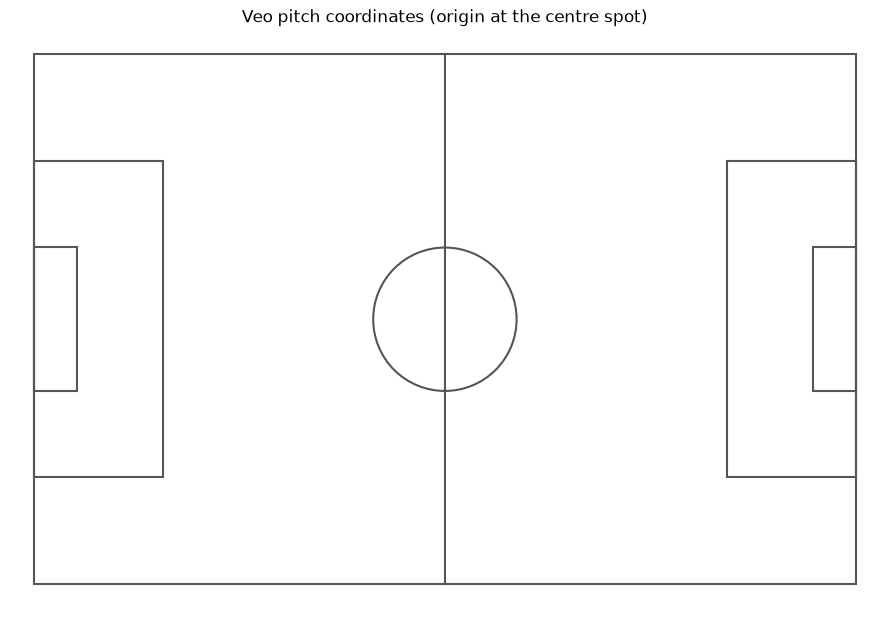

In [4]:
PITCH_L, PITCH_W = 105.0, 67.7
COLOURS = {"home": "#1f77b4", "away": "#d62728", "referee": "#999999"}

def draw_pitch(ax=None, figsize=(12, 7.5)):
    """Draw a pitch in Veo coordinates: x along, y across, origin at centre."""
    if ax is None:
        _, ax = plt.subplots(figsize=figsize)
    hl, hw = PITCH_L / 2, PITCH_W / 2
    ax.add_patch(plt.Rectangle((-hl, -hw), PITCH_L, PITCH_W, fill=False, lw=1.5, color="#555"))
    ax.plot([0, 0], [-hw, hw], color="#555", lw=1.5)
    ax.add_patch(plt.Circle((0, 0), 9.15, fill=False, lw=1.5, color="#555"))
    for s in (-1, 1):
        ax.add_patch(plt.Rectangle((s*hl, -20.15), -s*16.5, 40.3, fill=False, lw=1.5, color="#555"))
        ax.add_patch(plt.Rectangle((s*hl, -9.16),  -s*5.5,  18.32, fill=False, lw=1.5, color="#555"))
    ax.set_xlim(-hl-3, hl+3); ax.set_ylim(-hw-3, hw+3)
    ax.set_aspect("equal"); ax.axis("off")
    return ax

draw_pitch(); plt.title("Veo pitch coordinates (origin at the centre spot)"); plt.show()

## 4. One frame: 22 players and the ball

The ball is a column on every tracking row, so there is nothing to merge.


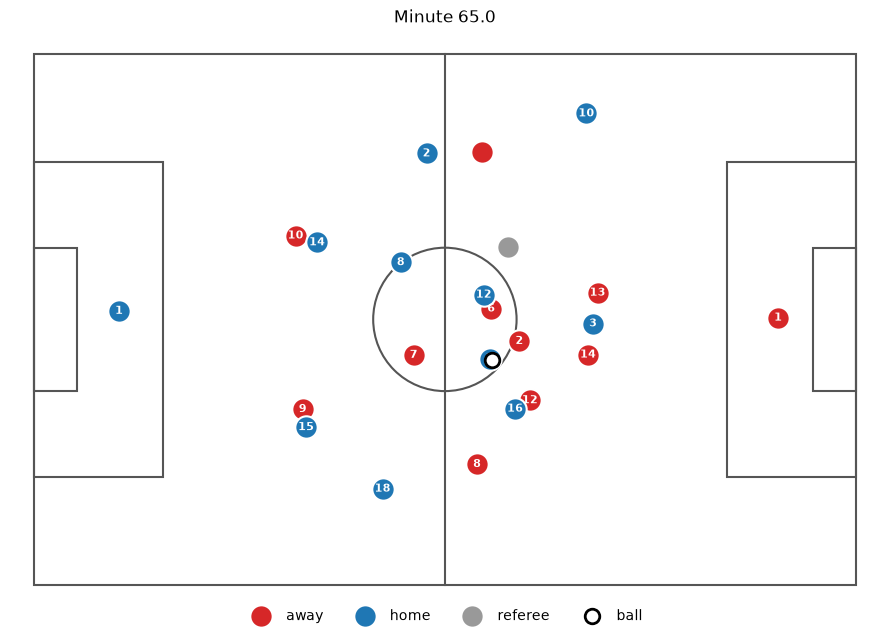

In [5]:
t = players.loc[(players.timestamp_ms > 3_900_000).idxmax(), "timestamp_ms"]
frame = players[players.timestamp_ms == t]

ax = draw_pitch()
for team, g in frame.groupby("team"):
    ax.scatter(g.x, g.y, s=260, c=COLOURS[team], edgecolor="white", lw=1.5, zorder=3, label=team)
    for r in g.itertuples():
        if pd.notna(r.player_id):
            ax.text(r.x, r.y, r.player_id.split("_")[1], ha="center", va="center",
                    color="white", fontsize=8, fontweight="bold", zorder=4)

b = frame.iloc[0]
if pd.notna(b.ball_x):
    ax.scatter(b.ball_x, b.ball_y, s=110, c="white", edgecolor="black", lw=2, zorder=5, label="ball")

ax.legend(loc="upper center", bbox_to_anchor=(0.5, 0.02), ncol=4, frameon=False)
plt.title(f"Minute {t/60000:.1f}"); plt.show()

## 5. Pass network

832 passes, most with the receiver resolved.


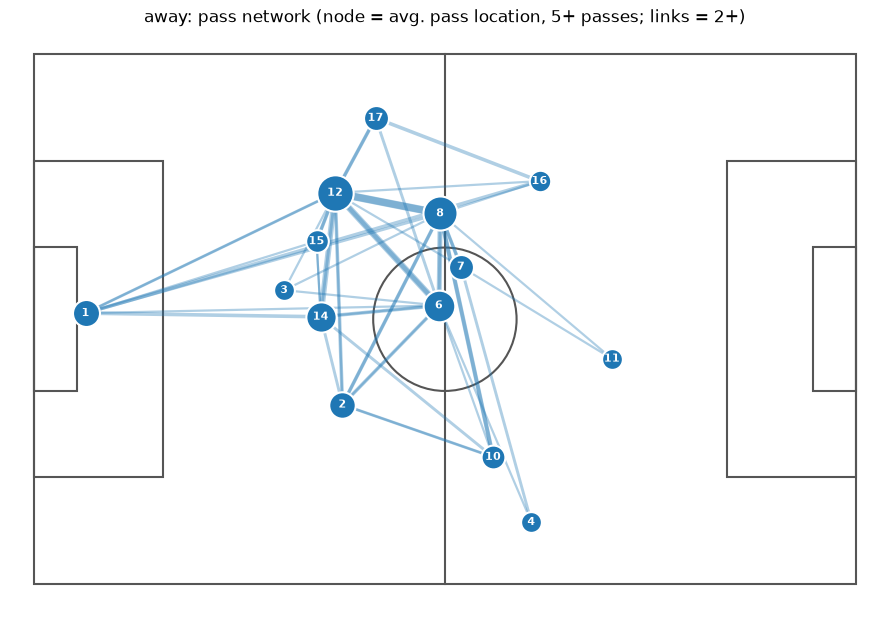

In [6]:
TEAM = "away"

pas = events[(events.event_name == "pass") & (events.team == TEAM) &
             events.player_id.notna() & events.receiver_player_id.notna() &
             (events.pass_success == True)]

# Node position = where the player actually plays their passes. Averaging raw
# tracking over the whole match collapses everyone into a blob.
# normalise to attacking direction so both halves stack: +x is always forward
pas = pas.assign(xa=pas.x_start * pas.attack_dir, ya=pas.y_start * pas.attack_dir)
pos = pas.groupby("player_id")[["xa", "ya"]].mean()
pos.columns = ["x", "y"]
vol = pas.player_id.value_counts()
pos = pos[vol.reindex(pos.index).fillna(0) >= 5]

link = pas.groupby(["player_id", "receiver_player_id"]).size().reset_index(name="n")
link = link[link.n >= 2]

ax = draw_pitch()
for r in link.itertuples():
    if r.player_id in pos.index and r.receiver_player_id in pos.index:
        a, b = pos.loc[r.player_id], pos.loc[r.receiver_player_id]
        ax.plot([a.x, b.x], [a.y, b.y], color="#1f77b4", alpha=0.35, lw=0.6 + r.n * 0.5, zorder=2)
for pid, pt in pos.iterrows():
    ax.scatter(pt.x, pt.y, s=140 + vol.get(pid, 0) * 14, c="#1f77b4",
               edgecolor="white", lw=1.5, zorder=3)
    ax.text(pt.x, pt.y, pid.split("_")[1], ha="center", va="center",
            color="white", fontsize=8, fontweight="bold", zorder=4)

plt.title(f"{TEAM}: pass network (node = avg. pass location, 5+ passes; links = 2+)")
plt.show()

## 6. Shots, goals, and the start of an xG model

`shot_distance_m` and `shot_angle_deg` are pre-computed: the two standard inputs to
an expected-goals model. 29 shots is far too few to *fit* one, but plenty to explore
the relationship, or to score the shots with a model you bring.

Four goals show here, not six. A shot map can only place a goal that has a shot
behind it, and two of the six do not. See the goals note in `DATA_DICTIONARY.md`.


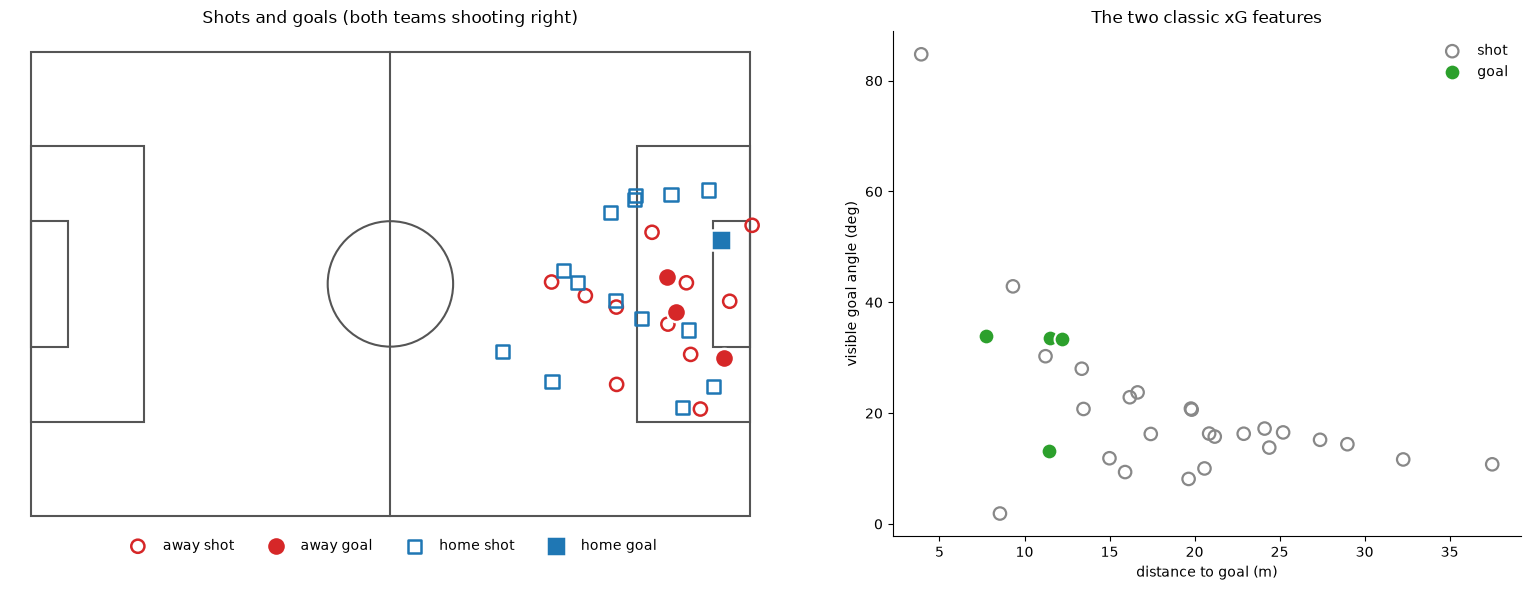

In [7]:
shots = events[(events.event_name == "shot") & events.x_start.notna()].copy()
# flip onto one end so both teams' shots overlay
shots["x_start"] = shots.x_start * shots.attack_dir
shots["y_start"] = shots.y_start * shots.attack_dir

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6),
                               gridspec_kw={"width_ratios": [1.4, 1]})
draw_pitch(ax1)
for team, mark in [("away", "o"), ("home", "s")]:
    s = shots[shots.team == team]
    ax1.scatter(s[~s.is_goal].x_start, s[~s.is_goal].y_start, s=90, marker=mark,
                facecolor="none", edgecolor=COLOURS[team], lw=1.8, zorder=3, label=f"{team} shot")
    ax1.scatter(s[s.is_goal].x_start, s[s.is_goal].y_start, s=190, marker=mark,
                c=COLOURS[team], edgecolor="white", lw=1.8, zorder=4, label=f"{team} goal")
ax1.legend(loc="upper center", bbox_to_anchor=(0.5, 0.02), ncol=4, frameon=False)
ax1.set_title("Shots and goals (both teams shooting right)")

ax2.scatter(shots[~shots.is_goal].shot_distance_m, shots[~shots.is_goal].shot_angle_deg,
            s=80, facecolor="none", edgecolor="#888", lw=1.6, label="shot")
ax2.scatter(shots[shots.is_goal].shot_distance_m, shots[shots.is_goal].shot_angle_deg,
            s=130, c="#2ca02c", edgecolor="white", lw=1.5, label="goal")
ax2.set_xlabel("distance to goal (m)"); ax2.set_ylabel("visible goal angle (deg)")
ax2.set_title("The two classic xG features"); ax2.legend(frameon=False)
ax2.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## Over to you

Some directions, none of them compulsory:

- **The scoreline:** these teams were near-identical on every process measure, and
  one won by two. Where does the difference actually live?
- **Pressing:** how quickly does a team close the ball down after losing it?
  (`ball_x`, `ball_y` are on every tracking row)
- **Space:** who finds space between the lines? That needs the tracking grid
- **Transitions:** `sequence_id` groups consecutive same-team events. What happens
  in the 10 seconds after possession changes hands?
- **Off-ball runs:** tracking sees the 21 players who *aren't* on the ball

Check anything surprising against the video.
